# Día 0 — Fechas y series de tiempo en Pandas

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Modalidad:** asincrónica (antes del Día 1)

En el Módulo 3 trabajamos con tablas donde **el orden de las filas no importaba**: podíamos mezclar clientes al azar y separar Train y Test sin problema. En este módulo cada fila es **un mes**, y el orden es la información más importante que tenemos.

Este notebook prepara las herramientas de Pandas que usaremos todos los días. No hay modelos todavía: solo aprenderemos a **leer, ordenar, desplazar, suavizar y agregar** series de tiempo.

> **pregunta → fechas → orden → frecuencia → transformación → gráfico**

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- cómo convertir texto en fechas con `pd.to_datetime`;
- qué es un **índice de fechas** y por qué facilita seleccionar periodos;
- qué hace `shift` y por qué un desplazamiento hacia el futuro es peligroso;
- cuál es la diferencia entre `diff` y `pct_change`;
- cómo se calcula un **promedio móvil** con `rolling`;
- cómo cambiar la frecuencia de una serie con `resample`, y por qué no todas las variables se agregan igual;
- cómo revisar una tabla real con varias series que empiezan en fechas distintas.

## Evaluación

Al inicio del Día 1 se aplica la **evaluación diagnóstica** (20 preguntas, no modifica la nota).

## 0. Librerías que usaremos

Partimos de **Anaconda + Jupyter** ya instalados. En este notebook solo necesitamos `numpy`, `pandas` y `matplotlib`. Si al ejecutar la siguiente celda aparece un error de módulo faltante, instálalo desde una celda nueva:

```python
%pip install pandas matplotlib
```

In [1]:
# Cálculo numérico y datos tabulares
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Rutas de archivos
from pathlib import Path

In [2]:
# Ubicamos la carpeta de datos sin depender de si Jupyter se abrió
# desde la carpeta raíz o desde la carpeta notebooks/.
DATA_DIR = Path('datos') if Path('datos').exists() else Path('../datos')

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /tmp/m5repo/datos


# 1. De texto a fecha: `pd.to_datetime`

Cuando un CSV se carga, las fechas llegan como **texto** (`object`). Para Pandas, `"2025-01-01"` es una palabra, no un día del calendario: no sabe ordenarla, restarla ni agruparla por mes.

La función `pd.to_datetime` convierte ese texto en un objeto de fecha (`datetime64`).

In [3]:
# Tres fechas escritas como texto.
fechas_texto = pd.Series(['2025-01-01', '2025-02-01', '2025-03-01'])

print('Tipo antes:', fechas_texto.dtype)

# Convertimos el texto en fechas reales.
fechas = pd.to_datetime(fechas_texto)

print('Tipo después:', fechas.dtype)
fechas

Tipo antes: str
Tipo después: datetime64[us]


0   2025-01-01
1   2025-02-01
2   2025-03-01
dtype: datetime64[us]

`object` significa "texto o mezcla de tipos". `datetime64[ns]` significa "fecha y hora". A partir de ahora Pandas entiende que enero va antes que febrero.

## 1.1 Formatos distintos

En Ecuador es común escribir el día primero: `15/01/2025`. Si no lo indicamos, Pandas podría leerlo como "mes 15", que no existe, o confundir `03/02/2025` (3 de febrero) con el 2 de marzo.

In [4]:
# Fechas con día primero, como se escriben en Ecuador.
texto_ec = pd.Series(['03/02/2025', '15/03/2025', '30/04/2025'])

# dayfirst=True le dice a Pandas que el primer número es el día.
print(pd.to_datetime(texto_ec, dayfirst=True))

# Si conocemos el formato exacto, es más seguro indicarlo con format=.
# %d = día, %m = mes, %Y = año con cuatro dígitos.
print(pd.to_datetime(texto_ec, format='%d/%m/%Y'))

0   2025-02-03
1   2025-03-15
2   2025-04-30
dtype: datetime64[us]
0   2025-02-03
1   2025-03-15
2   2025-04-30
dtype: datetime64[us]


| Código | Significado | Ejemplo |
|---|---|---|
| `%Y` | año con cuatro dígitos | 2025 |
| `%m` | mes con dos dígitos | 03 |
| `%d` | día con dos dígitos | 15 |
| `%b` | mes abreviado (en inglés) | Mar |

**Regla práctica:** si sabes el formato, escríbelo con `format=`. Si un texto no encaja, Pandas mostrará un error en lugar de inventar una fecha.

## 1.2 Partes de una fecha: el accesor `.dt`

Una vez convertida, cada fecha tiene año, mes, trimestre y nombre del día. Se consultan con `.dt`.

In [5]:
ejemplo = pd.DataFrame({'fecha': pd.to_datetime(['2024-04-01', '2024-09-01', '2025-01-01'])})

ejemplo['anio'] = ejemplo['fecha'].dt.year      # año
ejemplo['mes'] = ejemplo['fecha'].dt.month      # número de mes, 1 a 12
ejemplo['trimestre'] = ejemplo['fecha'].dt.quarter  # 1 a 4

ejemplo

,fecha,anio,mes,trimestre
0,2024-04-01,2024,4,2
1,2024-09-01,2024,9,3
2,2025-01-01,2025,1,1


Estas columnas serán muy útiles el Día 4: el **mes del año** puede ser una variable predictora cuando una serie tiene estacionalidad.

## 1.3 Crear un calendario: `pd.date_range`

A veces necesitamos generar fechas en lugar de leerlas, por ejemplo para los meses que vamos a pronosticar.

In [6]:
# 6 meses, empezando en enero de 2026.
# freq='MS' = Month Start: el primer día de cada mes.
meses = pd.date_range(start='2026-01-01', periods=6, freq='MS')
print(meses)

# Otras frecuencias útiles.
print(pd.date_range('2026-01-01', periods=4, freq='QS'))   # inicio de trimestre
print(pd.date_range('2026-01-01', periods=5, freq='D'))    # días
print(pd.date_range('2026-01-01', periods=3, freq='YS'))   # inicio de año

DatetimeIndex(['2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01',
               '2026-05-01', '2026-06-01'],
              dtype='datetime64[us]', freq='MS')
DatetimeIndex(['2026-01-01', '2026-04-01', '2026-07-01', '2026-10-01'], dtype='datetime64[us]', freq='QS-JAN')
DatetimeIndex(['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04',
               '2026-01-05'],
              dtype='datetime64[us]', freq='D')
DatetimeIndex(['2026-01-01', '2027-01-01', '2028-01-01'], dtype='datetime64[us]', freq='YS-JAN')


| `freq` | Significado |
|---|---|
| `'D'` | diaria |
| `'W'` | semanal |
| `'MS'` | mensual, primer día del mes |
| `'QS'` | trimestral, primer día del trimestre |
| `'YS'` | anual, primer día del año |

En este módulo casi todas las series son **mensuales** y usan la convención `MS`: el valor de enero de 2026 se guarda con la fecha `2026-01-01`, aunque se refiera a todo el mes.

# 2. El índice de fechas

En el Módulo 3 el índice de un DataFrame era un número de fila (0, 1, 2…). En series de tiempo conviene que el índice **sea la fecha**. Así podemos pedir "todo 2024" o "de marzo a junio" sin escribir filtros.

Usaremos una serie pequeña de 12 meses para practicar. Los valores son la **inflación mensual del Ecuador en 2024** (INEC, en porcentaje).

In [7]:
inflacion_2024 = pd.Series(
    [0.13, 0.09, 0.29, 1.27, -0.12, -0.95, 0.93, 0.22, 0.18, -0.24, -0.26, -0.99],
    index=pd.date_range('2024-01-01', periods=12, freq='MS'),
    name='inflacion_mensual'
)

inflacion_2024

2024-01-01    0.13
2024-02-01    0.09
2024-03-01    0.29
2024-04-01    1.27
2024-05-01   -0.12
2024-06-01   -0.95
2024-07-01    0.93
2024-08-01    0.22
2024-09-01    0.18
2024-10-01   -0.24
2024-11-01   -0.26
2024-12-01   -0.99
Freq: MS, Name: inflacion_mensual, dtype: float64

In [8]:
# Seleccionar por texto de fecha: Pandas entiende años y meses.
print('Abril 2024:', inflacion_2024.loc['2024-04'].values)

# Un rango: de marzo a junio, ambos incluidos.
print(inflacion_2024.loc['2024-03':'2024-06'])

Abril 2024: [1.27]
2024-03-01    0.29
2024-04-01    1.27
2024-05-01   -0.12
2024-06-01   -0.95
Freq: MS, Name: inflacion_mensual, dtype: float64


Con un índice numérico tendríamos que recordar que abril es la fila 3. Con un índice de fechas, el código se lee como la pregunta: **"dame abril de 2024"**.

## 2.1 El orden importa

Si las filas llegan desordenadas, cualquier cálculo que dependa del "mes anterior" será incorrecto. Siempre ordenamos con `sort_index()`.

In [9]:
# Desordenamos a propósito.
desordenada = inflacion_2024.sample(frac=1, random_state=1)
print(desordenada.head(4))

# sort_index() ordena por la fecha del índice.
ordenada = desordenada.sort_index()
print(ordenada.head(4))

2024-03-01    0.29
2024-04-01    1.27
2024-05-01   -0.12
2024-11-01   -0.26
Name: inflacion_mensual, dtype: float64
2024-01-01    0.13
2024-02-01    0.09
2024-03-01    0.29
2024-04-01    1.27
Name: inflacion_mensual, dtype: float64


## 2.2 Meses faltantes: `asfreq`

Una serie mensual debe tener **un registro por mes**. Si falta un mes, no aparece como `NaN`: simplemente no está, y un cálculo como "el mes anterior" saltaría dos meses sin avisar.

`asfreq('MS')` reconstruye el calendario completo y deja `NaN` donde no hay dato.

In [10]:
# Quitamos mayo y agosto para simular un archivo incompleto.
incompleta = inflacion_2024.drop(pd.to_datetime(['2024-05-01', '2024-08-01']))
print('Filas en el archivo:', len(incompleta))

completa = incompleta.asfreq('MS')
print('Filas después de asfreq:', len(completa))
print('Meses sin dato:', completa[completa.isna()].index.strftime('%Y-%m').tolist())

Filas en el archivo: 10
Filas después de asfreq: 12
Meses sin dato: ['2024-05', '2024-08']


Ahora el problema es visible. Qué hacer con esos `NaN` depende del caso: esperar el dato oficial, interpolar o excluir el periodo. Lo importante es **saber que faltan**.

# 3. Desplazar en el tiempo: `shift`

`shift(k)` mueve los valores **k posiciones hacia abajo**. Así, en la fila de un mes aparece el valor de **k meses antes**. Ese valor se llama **rezago** (*lag*) y es la base de casi todos los pronósticos.

## 3.1 A mano, con seis meses

| Mes | Inflación | `shift(1)` | `shift(2)` | `shift(-1)` |
|---|---:|---:|---:|---:|
| ene | 0.13 | — | — | 0.09 |
| feb | 0.09 | 0.13 | — | 0.29 |
| mar | 0.29 | 0.09 | 0.13 | 1.27 |
| abr | 1.27 | 0.29 | 0.09 | −0.12 |
| may | −0.12 | 1.27 | 0.29 | −0.95 |
| jun | −0.95 | −0.12 | 1.27 | — |

- `shift(1)` en marzo muestra el dato de **febrero**: es información que ya conocíamos en marzo.
- `shift(-1)` en marzo muestra el dato de **abril**: es el **futuro**.

Comprobemos la tabla con Pandas.

In [11]:
tabla = pd.DataFrame({'inflacion': inflacion_2024.iloc[:6]})

tabla['rezago_1'] = tabla['inflacion'].shift(1)    # valor del mes anterior
tabla['rezago_2'] = tabla['inflacion'].shift(2)    # valor de hace dos meses
tabla['futuro_1'] = tabla['inflacion'].shift(-1)   # valor del mes siguiente

tabla

,inflacion,rezago_1,rezago_2,futuro_1
2024-01-01,0.13,NaN,NaN,0.09
2024-02-01,0.09,0.13,NaN,0.29
2024-03-01,0.29,0.09,0.13,1.27
2024-04-01,1.27,0.29,0.09,-0.12
2024-05-01,-0.12,1.27,0.29,-0.95
2024-06-01,-0.95,-0.12,1.27,NaN


### Cuidado con `shift(-1)`: fuga de información

En el Módulo 3 vimos que una variable que solo se conoce **después** de decidir (como la duración de una llamada) produce resultados demasiado optimistas. En series de tiempo ocurre lo mismo con `shift` negativo.

- `shift(1)`, `shift(2)`, `shift(12)`: **permitidos como predictores**, porque son pasado.
- `shift(-1)`: solo sirve para construir el **objetivo** (lo que queremos predecir), nunca como predictor.

Los primeros meses quedan con `NaN` porque no existe un mes anterior al primero. Al construir la tabla de un modelo, esas filas se eliminan.

## 3.2 Un primer pronóstico: "el próximo mes será igual a este"

`shift(1)` ya es un pronóstico: el **pronóstico ingenuo** dice que el valor de cada mes será igual al del mes anterior. Lo estudiaremos el Día 1.

In [12]:
pronostico_ingenuo = inflacion_2024.shift(1)

error = inflacion_2024 - pronostico_ingenuo

comparacion = pd.DataFrame({
    'real': inflacion_2024,
    'pronostico_ingenuo': pronostico_ingenuo,
    'error': error.round(2)
})
comparacion

,real,pronostico_ingenuo,error
2024-01-01,0.13,NaN,NaN
2024-02-01,0.09,0.13,-0.04
2024-03-01,0.29,0.09,0.20
2024-04-01,1.27,0.29,0.98
2024-05-01,-0.12,1.27,-1.39
2024-06-01,-0.95,-0.12,-0.83
2024-07-01,0.93,-0.95,1.88
2024-08-01,0.22,0.93,-0.71
2024-09-01,0.18,0.22,-0.04
2024-10-01,-0.24,0.18,-0.42


In [13]:
# Error absoluto medio del pronóstico ingenuo en 2024 (sin el primer mes, que no tiene pronóstico).
print('MAE ingenuo 2024:', round(error.abs().mean(), 3), 'puntos porcentuales')

MAE ingenuo 2024: 0.658 puntos porcentuales


# 4. Cambios: `diff` y `pct_change`

Dos preguntas distintas sobre el mismo par de meses:

- **¿Cuánto cambió?** → diferencia absoluta: $y_t - y_{t-1}$ → `diff()`
- **¿En qué porcentaje cambió?** → variación relativa: $\dfrac{y_t - y_{t-1}}{y_{t-1}}$ → `pct_change()`

## 4.1 A mano

Un índice de precios pasa de 100 a 102 y luego a 101:

| Mes | Índice | `diff()` | `pct_change()` × 100 |
|---|---:|---:|---:|
| 1 | 100 | — | — |
| 2 | 102 | 102 − 100 = 2 | 2 / 100 = 2.00 % |
| 3 | 101 | 101 − 102 = −1 | −1 / 102 = −0.98 % |

In [14]:
indice = pd.Series([100, 102, 101], index=pd.date_range('2026-01-01', periods=3, freq='MS'))

pd.DataFrame({
    'indice': indice,
    'diff': indice.diff(),
    'pct_change_%': (indice.pct_change() * 100).round(2)
})

,indice,diff,pct_change_%
2026-01-01,100,NaN,NaN
2026-02-01,102,2.0,2.00
2026-03-01,101,-1.0,-0.98


**La inflación mensual es exactamente `pct_change()` del IPC.** Lo comprobaremos con los datos oficiales en la sección 7.

## 4.2 Diferencia de 12 meses

`diff(12)` compara cada mes con **el mismo mes del año anterior**. Sirve para eliminar la estacionalidad: enero se compara con enero, septiembre con septiembre. La **inflación anual** es `pct_change(12)` del índice.

El Día 2 usaremos `diff` para volver estacionaria una serie, un requisito de los modelos ARIMA.

# 5. Suavizar: `rolling`

Un **promedio móvil** de 3 meses reemplaza cada valor por el promedio de ese mes y los dos anteriores. Reduce el ruido y deja ver la dirección general.

## 5.1 A mano

Con la inflación de enero a mayo de 2024:

| Mes | Inflación | Promedio móvil 3 |
|---|---:|---:|
| ene | 0.13 | — |
| feb | 0.09 | — |
| mar | 0.29 | (0.13 + 0.09 + 0.29) / 3 = 0.170 |
| abr | 1.27 | (0.09 + 0.29 + 1.27) / 3 = 0.550 |
| may | −0.12 | (0.29 + 1.27 − 0.12) / 3 = 0.480 |

In [15]:
pm3 = inflacion_2024.rolling(window=3).mean()

pd.DataFrame({'inflacion': inflacion_2024, 'promedio_movil_3': pm3.round(3)}).head(6)

,inflacion,promedio_movil_3
2024-01-01,0.13,NaN
2024-02-01,0.09,NaN
2024-03-01,0.29,0.170
2024-04-01,1.27,0.550
2024-05-01,-0.12,0.480
2024-06-01,-0.95,0.067


### Los parámetros de `rolling`, uno por uno

| Parámetro | Qué hace | Valor por defecto |
|---|---|---|
| `window` | cuántos periodos entran en cada cálculo | obligatorio |
| `min_periods` | cuántos datos mínimos para calcular (si hay menos, `NaN`) | igual a `window` |
| `center` | si `True`, la ventana se centra en el mes; si `False`, solo usa pasado | `False` |

Para **pronosticar** usamos siempre `center=False`: una ventana centrada mira meses futuros. Para **describir** una tendencia histórica (Día 1, descomposición) sí se usa una ventana centrada.

Además de `.mean()`, una ventana móvil puede calcular `.std()`, `.min()`, `.max()` o `.sum()`.

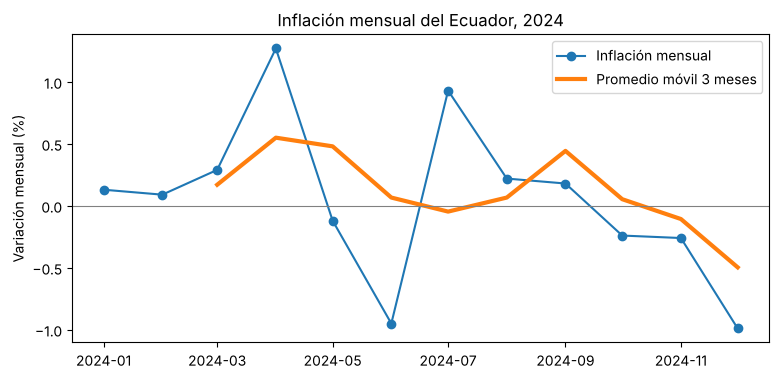

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(inflacion_2024, marker='o', label='Inflación mensual')
ax.plot(inflacion_2024.rolling(3).mean(), linewidth=3, label='Promedio móvil 3 meses')

ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Variación mensual (%)')
ax.set_title('Inflación mensual del Ecuador, 2024')
ax.legend()
plt.show()

El promedio móvil reacciona más lento: el pico de abril (1.27 %) se reparte entre abril, mayo y junio. **Suavizar es útil para ver la tendencia, pero hace llegar tarde las señales.**

# 6. Cambiar de frecuencia: `resample`

`resample` agrupa una serie en periodos más largos (de días a meses, de meses a trimestres) y aplica una función a cada grupo. Funciona como un `groupby` por calendario.

La decisión importante es **qué función usar**, y depende del tipo de variable:

| Tipo de variable | Ejemplo | Para pasar de mensual a anual |
|---|---|---|
| **Flujo**: se acumula durante el periodo | exportaciones del mes | `sum()` |
| **Saldo** (*stock*): se mide en un momento | reservas internacionales | `last()` |
| **Tasa o precio**: un nivel promedio | tasa de interés, precio del petróleo | `mean()` |
| **Índice** | IPC | `mean()` del año, o `last()` para diciembre |

Sumar reservas internacionales de 12 meses no tiene sentido económico; promediar exportaciones daría un "mes típico", no el total del año.

In [17]:
# Inflación mensual a trimestral: sumamos las variaciones del trimestre.
# (Para variaciones pequeñas, la suma se aproxima a la variación acumulada.)
trimestral = inflacion_2024.resample('QS').sum().round(2)
trimestral

2024-01-01    0.51
2024-04-01    0.20
2024-07-01    1.33
2024-10-01   -1.49
Freq: QS-JAN, Name: inflacion_mensual, dtype: float64

`'QS'` agrupa enero–marzo, abril–junio, julio–septiembre y octubre–diciembre, y etiqueta cada grupo con el primer día del trimestre.

# 7. Datos reales: `series_economicas.csv`

Este es el archivo principal del módulo. Tiene **una fila por mes** desde enero de 1969 y **una columna por indicador**. Los datos son oficiales y públicos:

| Columna | Fuente | Unidad | Desde |
|---|---|---|---|
| `ipc_indice`, `ipc_var_mensual` | INEC | índice / % | 1969 |
| `exportaciones_fob_musd`, `exportaciones_petroleras_musd`, `importaciones_fob_musd`, `balanza_comercial_musd` | BCE | millones USD FOB | 1990 |
| `riesgo_pais_pb` | BCE (EMBI, promedio del mes) | puntos básicos | 2000 |
| `reservas_internacionales_musd`, `liquidez_m2_musd` | BCE | millones USD | 2000 |
| `precio_crudo_oriente_usd`, `precio_wti_usd` | BCE | USD por barril | 2000 |
| `salario_real_indice` | BCE | índice | 2002 |
| `tasa_activa_ref_pct`, `tasa_pasiva_ref_pct` | BCE | % | 2015 |

Cada indicador empieza cuando su fuente empezó a publicarlo, por eso habrá muchos `NaN` en los primeros años.

In [18]:
# parse_dates convierte la columna fecha al leer el archivo.
# index_col la deja como índice desde el inicio.
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha')

print('shape:', series.shape)
series.tail()

shape: (695, 14)


,ipc_indice,ipc_var_mensual,tasa_activa_ref_pct,tasa_pasiva_ref_pct,liquidez_m2_musd,reservas_internacionales_musd,exportaciones_fob_musd,exportaciones_petroleras_musd,importaciones_fob_musd,balanza_comercial_musd,riesgo_pais_pb,precio_crudo_oriente_usd,precio_wti_usd,salario_real_indice
fecha,,,,,,,,,,,,,,
2026-07-01,100.794745,-0.089334,6.91,5.19,104206.976563,11345.576741,3717.921551,804.010450,3213.482477,504.439074,421.007174,77.201284,78.97,100.461018
2026-08-01,100.838024,0.042938,6.79,5.10,104712.971152,12067.469663,3509.096599,923.159446,3298.141060,210.955540,429.511924,78.340604,82.66,100.417901
2026-09-01,NaN,NaN,7.03,4.99,NaN,11775.110916,NaN,NaN,NaN,NaN,438.608512,NaN,NaN,100.116824
2026-10-01,NaN,NaN,6.96,4.93,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-11-01,NaN,NaN,6.88,4.83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# info() muestra cuántos valores no nulos tiene cada columna.
series.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 695 entries, 1969-01-01 to 2026-11-01
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   ipc_indice                     692 non-null    float64
 1   ipc_var_mensual                691 non-null    float64
 2   tasa_activa_ref_pct            143 non-null    float64
 3   tasa_pasiva_ref_pct            143 non-null    float64
 4   liquidez_m2_musd               320 non-null    float64
 5   reservas_internacionales_musd  321 non-null    float64
 6   exportaciones_fob_musd         440 non-null    float64
 7   exportaciones_petroleras_musd  440 non-null    float64
 8   importaciones_fob_musd         440 non-null    float64
 9   balanza_comercial_musd         440 non-null    float64
 10  riesgo_pais_pb                 321 non-null    float64
 11  precio_crudo_oriente_usd       320 non-null    float64
 12  precio_wti_usd                 320 non-nul

Todas las columnas son `float64` y el índice es `DatetimeIndex`. Las cantidades de valores no nulos son muy distintas: eso es esperado, porque las series empiezan en años distintos.

## 7.1 ¿Desde cuándo y hasta cuándo hay datos?

`first_valid_index()` y `last_valid_index()` responden esa pregunta para cada columna.

In [20]:
cobertura = pd.DataFrame({
    'desde': series.apply(lambda col: col.first_valid_index()),
    'hasta': series.apply(lambda col: col.last_valid_index()),
    'observaciones': series.notna().sum(),
})

# Meses con NaN entre el inicio y el final de cada serie (huecos internos).
cobertura['huecos_internos'] = [
    series[col].loc[cobertura.loc[col, 'desde']:cobertura.loc[col, 'hasta']].isna().sum()
    for col in series.columns
]

cobertura.sort_values('desde')

,desde,hasta,observaciones,huecos_internos
ipc_indice,1969-01-01,2026-08-01,692,0
ipc_var_mensual,1969-02-01,2026-08-01,691,0
exportaciones_fob_musd,1990-01-01,2026-08-01,440,0
exportaciones_petroleras_musd,1990-01-01,2026-08-01,440,0
importaciones_fob_musd,1990-01-01,2026-08-01,440,0
balanza_comercial_musd,1990-01-01,2026-08-01,440,0
liquidez_m2_musd,2000-01-01,2026-08-01,320,0
reservas_internacionales_musd,2000-01-01,2026-09-01,321,0
riesgo_pais_pb,2000-01-01,2026-09-01,321,0
precio_crudo_oriente_usd,2000-01-01,2026-08-01,320,0


La columna `huecos_internos` debería ser 0 en todas: si una serie tuviera meses vacíos en medio, habría que decidir qué hacer antes de modelar. También vemos que los últimos datos no llegan al mismo mes: cada institución publica con un rezago distinto.

## 7.2 Comprobar que el índice tiene frecuencia mensual

In [21]:
# ¿El calendario está completo? Comparamos con un calendario mensual ideal.
calendario = pd.date_range(series.index.min(), series.index.max(), freq='MS')

print('Meses esperados:', len(calendario))
print('Meses en el archivo:', len(series))
print('¿Fechas repetidas?:', series.index.duplicated().any())

# Fijamos la frecuencia mensual de forma explícita.
series = series.asfreq('MS')
print('Frecuencia del índice:', series.index.freqstr)

Meses esperados: 695
Meses en el archivo: 695
¿Fechas repetidas?: False
Frecuencia del índice: MS


## 7.3 La inflación mensual oficial es `pct_change()` del IPC

El INEC publica el índice (`ipc_indice`) y la variación mensual (`ipc_var_mensual`). Si la sección 4 es correcta, calcular `pct_change()` sobre el índice debe reproducir la variación oficial.

In [22]:
calculada = series['ipc_indice'].pct_change() * 100

comparacion_ipc = pd.DataFrame({
    'oficial_INEC': series['ipc_var_mensual'],
    'calculada_pct_change': calculada
}).dropna()

comparacion_ipc['diferencia'] = comparacion_ipc['oficial_INEC'] - comparacion_ipc['calculada_pct_change']

print('Mayor diferencia absoluta:', comparacion_ipc['diferencia'].abs().max().round(6))
comparacion_ipc.tail(6).round(4)

Mayor diferencia absoluta: 0.006662


,oficial_INEC,calculada_pct_change,diferencia
fecha,,,
2026-03-01,0.1235,0.1235,0.0
2026-04-01,0.5256,0.5256,-0.0
2026-05-01,-0.6213,-0.6213,0.0
2026-06-01,0.7887,0.7887,-0.0
2026-07-01,-0.0893,-0.0893,0.0
2026-08-01,0.0429,0.0429,0.0


La diferencia es prácticamente cero: la variación mensual oficial **es** el cambio porcentual del índice. Con esto sabemos que podemos calcular cualquier otra variación desde el índice, por ejemplo la **inflación anual**.

In [23]:
# Inflación anual: cambio porcentual respecto al mismo mes del año anterior.
series['ipc_var_anual'] = series['ipc_indice'].pct_change(12) * 100

series[['ipc_indice', 'ipc_var_mensual', 'ipc_var_anual']].loc['2025-09':].round(2)

,ipc_indice,ipc_var_mensual,ipc_var_anual
fecha,,,
2025-09-01,99.80,0.08,0.72
2025-10-01,100.08,0.28,1.24
2025-11-01,99.64,-0.44,1.05
2025-12-01,99.50,-0.14,1.91
2026-01-01,99.86,0.37,2.44
2026-02-01,100.07,0.21,2.56
2026-03-01,100.19,0.12,2.33
2026-04-01,100.72,0.53,2.60
2026-05-01,100.10,-0.62,0.92


## 7.4 Mirar la serie completa: la dolarización

Grafiquemos la inflación anual desde 1970.

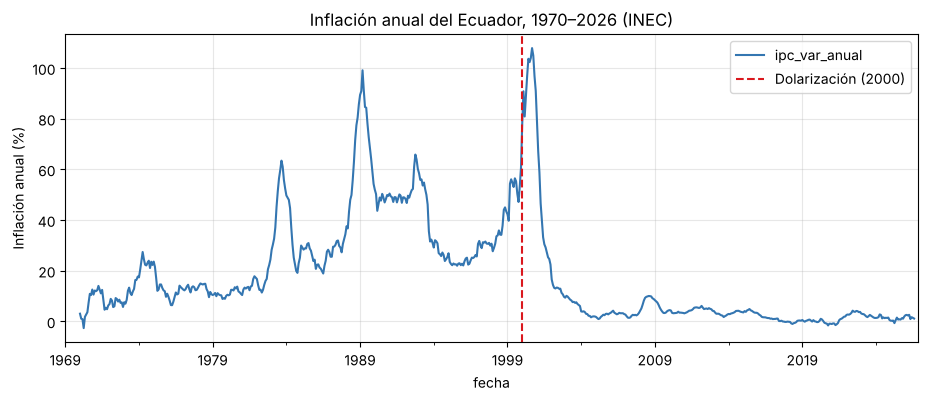

Máxima inflación anual: 107.9 % en Sep 2000


In [24]:
fig, ax = plt.subplots(figsize=(11, 4))

series['ipc_var_anual'].plot(ax=ax, color='#3476B1')

ax.axvline(pd.Timestamp('2000-01-01'), color='#DA181E', linestyle='--', label='Dolarización (2000)')
ax.set_ylabel('Inflación anual (%)')
ax.set_title('Inflación anual del Ecuador, 1970–2026 (INEC)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print('Máxima inflación anual:', series['ipc_var_anual'].max().round(1), '% en',
      series['ipc_var_anual'].idxmax().strftime('%b %Y'))

Antes de 2001 la inflación anual llegó a niveles muy superiores a los actuales. Después de la dolarización la serie cambia de comportamiento: valores bajos, cercanos a 0–5 %.

**Consecuencia para el módulo:** si queremos pronosticar la inflación de hoy, no conviene enseñarle a un modelo la dinámica de la hiperinflación. Por eso, desde el Día 1, usaremos la inflación mensual **desde 2005**. Este tipo de quiebre se llama **cambio estructural** y lo estudiaremos el Día 5.

In [25]:
# Seleccionamos el periodo de trabajo con texto de fecha, como en la sección 2.
inflacion = series['ipc_var_mensual'].loc['2005':].dropna()

print(len(inflacion), 'meses, de', inflacion.index.min().strftime('%b %Y'), 'a', inflacion.index.max().strftime('%b %Y'))

260 meses, de Jan 2005 a Aug 2026


## 7.5 `rolling` sobre la serie real

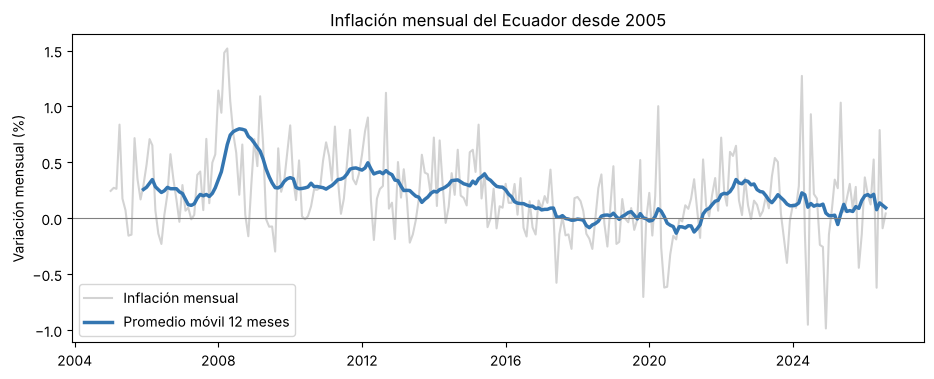

In [26]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(inflacion, color='lightgray', label='Inflación mensual')
ax.plot(inflacion.rolling(12).mean(), color='#3476B1', linewidth=2.5, label='Promedio móvil 12 meses')

ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Variación mensual (%)')
ax.set_title('Inflación mensual del Ecuador desde 2005')
ax.legend()
plt.show()

El promedio de 12 meses deja ver periodos: inflación más alta en 2008 (crisis mundial de precios de alimentos), descenso hasta 2017–2020 con meses negativos, y un nuevo aumento desde 2022. Esto se acerca a lo que llamaremos **tendencia** el Día 1.

## 7.6 `resample` sobre la serie real: flujos y saldos

Pasemos dos variables del BCE de mensual a anual, aplicando la regla de la sección 6.

In [27]:
anual = pd.DataFrame({
    # Flujo: el total exportado en el año es la suma de los 12 meses.
    'exportaciones_anuales_musd': series['exportaciones_fob_musd'].resample('YS').sum(min_count=12),
    # Saldo: las reservas a fin de año son las de diciembre.
    'reservas_fin_de_anio_musd': series['reservas_internacionales_musd'].resample('YS').last(),
    # Precio: el precio promedio del año.
    'precio_wti_promedio_usd': series['precio_wti_usd'].resample('YS').mean(),
})

anual.loc['2018':'2025'].round(0)

,exportaciones_anuales_musd,reservas_fin_de_anio_musd,precio_wti_promedio_usd
fecha,,,
2018-01-01,21653.0,2677.0,65.0
2019-01-01,22234.0,3397.0,57.0
2020-01-01,20334.0,7196.0,39.0
2021-01-01,26699.0,7898.0,68.0
2022-01-01,32658.0,8459.0,94.0
2023-01-01,31127.0,4454.0,78.0
2024-01-01,34421.0,6900.0,76.0
2025-01-01,37152.0,9795.0,65.0


`min_count=12` evita sumar años incompletos: si un año tiene menos de 12 meses con dato, el resultado queda `NaN` en lugar de un total engañosamente bajo. Por eso 2026 no aparece en la suma de exportaciones.

## 7.7 De diario a mensual: el precio del petróleo

En `datos/complementarios/` está el precio diario del petróleo WTI desde 1986 (EIA de EE. UU.). Lo llevamos a frecuencia mensual con `resample('MS').mean()` y lo comparamos con la serie mensual del BCE.

In [28]:
petroleo = pd.read_csv(DATA_DIR / 'complementarios' / 'petroleo_wti_brent_diario.csv',
                       parse_dates=['fecha'], index_col='fecha')

print('Observaciones diarias:', len(petroleo))
print(petroleo.head(3))

# De diario a mensual: promedio de los días con cotización de cada mes.
wti_mensual_eia = petroleo['wti_usd_barril'].resample('MS').mean()

comparacion_wti = pd.DataFrame({
    'WTI_BCE': series['precio_wti_usd'],
    'WTI_EIA_promedio_diario': wti_mensual_eia
}).dropna()

comparacion_wti['diferencia'] = comparacion_wti['WTI_BCE'] - comparacion_wti['WTI_EIA_promedio_diario']
print('\nMeses comparados:', len(comparacion_wti))
print('Diferencia absoluta media:', comparacion_wti['diferencia'].abs().mean().round(2), 'USD')

Observaciones diarias: 10224
            wti_usd_barril  brent_usd_barril
fecha                                       
1986-01-02           25.56               NaN
1986-01-03           26.00               NaN
1986-01-06           26.53               NaN

Meses comparados: 320
Diferencia absoluta media: 0.23 USD


Las dos fuentes coinciden en casi todos los meses (diferencias de centavos). En algunos meses recientes la diferencia es de unos pocos dólares, por el método de promedio y la fecha de corte de cada institución. **Cuando combines fuentes, compara antes de mezclar.**

En los días de cotización hay huecos (fines de semana y feriados): una serie diaria de precios **no** tiene 365 datos al año, y eso es normal.

# 8. Errores frecuentes con series de tiempo

| Error | Qué ocurre | Cómo evitarlo |
|---|---|---|
| Fechas como texto | no se pueden ordenar ni seleccionar por periodo | `pd.to_datetime` o `parse_dates` |
| Filas desordenadas | `shift` y `rolling` usan el mes equivocado | `sort_index()` |
| Meses faltantes invisibles | "el mes anterior" salta dos meses | `asfreq('MS')` y revisar `NaN` |
| Fechas repetidas | dos valores para el mismo mes | `index.duplicated()` |
| `shift(-1)` como predictor | el modelo usa el futuro | solo rezagos positivos como X |
| `rolling(center=True)` para pronosticar | la ventana incluye meses futuros | `center=False` |
| Sumar saldos o promediar flujos | totales anuales sin sentido | elegir `sum`, `last` o `mean` según el tipo |
| Mezclar periodos con comportamientos distintos | el modelo aprende una economía que ya no existe | revisar la serie completa y elegir el periodo |

# 9. Ejercicios autónomos

Resuélvelos en celdas nuevas debajo de cada enunciado. Las respuestas se revisan al inicio del Día 1.

1. **Fechas:** convierte `['31/12/2025', '01/01/2026', '15/02/2026']` a fechas con `format=` y calcula cuántos días hay entre la primera y la última (resta dos fechas).
2. **Índice:** con `inflacion`, muestra los valores de septiembre de todos los años desde 2015. Pista: `inflacion[inflacion.index.month == 9]`.
3. **`shift`:** crea una tabla con la inflación mensual de 2025 y sus rezagos 1 y 12. ¿Cuántas filas quedan sin `NaN`?
4. **`diff` y `pct_change`:** calcula la variación mensual de `reservas_internacionales_musd` en millones (`diff`) y en porcentaje (`pct_change`). ¿En qué mes desde 2015 aumentaron más en porcentaje?
5. **`rolling`:** calcula el promedio móvil de 3 y de 12 meses del riesgo país desde 2015 y grafícalos juntos. ¿Cuál reacciona primero a los cambios?
6. **`resample`:** obtén el total anual de importaciones FOB y el saldo de la balanza comercial anual desde 2010. ¿Qué función usaste para cada uno y por qué?

In [29]:
# Ejercicio 1

In [30]:
# Ejercicio 2

In [31]:
# Ejercicio 3

In [32]:
# Ejercicio 4

In [33]:
# Ejercicio 5

In [34]:
# Ejercicio 6

## Checklist antes de cualquier serie de tiempo

- [ ] ¿La columna de fecha es `datetime64`?
- [ ] ¿La fecha es el índice y está ordenada?
- [ ] ¿La frecuencia es la esperada (`asfreq`) y no hay fechas repetidas?
- [ ] ¿Sé desde cuándo y hasta cuándo hay datos, y si hay huecos internos?
- [ ] ¿Sé si la variable es un flujo, un saldo, una tasa o un índice?
- [ ] ¿Los predictores usan solo información pasada?
- [ ] ¿El periodo elegido representa la economía que quiero pronosticar?

**Puente hacia el Día 1:** ya sabemos manipular la serie. Mañana la descompondremos en tendencia, estacionalidad y ruido, y haremos los primeros pronósticos.